# Critical-amplitude minimisation

A clean working notebook for the fixed-grid evolution and gradient-descent experiment. The cells define the simulation and search; the expensive search runs only when `run_gradient_descent_batch()` is called. Regridding will be added in a separate section after its state-transfer test passes.


## Imports


In [1]:
import sys
sys.path.append("../source")

import pickle
from pathlib import Path
from math import isfinite

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse


In [ ]:
def check_regrid_needed(
    state,
    derivs,
    scalar_idx,
    num_ghosts=3,
    threshold=15.0,
):
    u = state[scalar_idx]
    dx = derivs.dx

    # dxn_matrix[2] is the unscaled second-derivative stencil.
    u_xx = (derivs.dxn_matrix[2] @ u) / (dx * dx)

    n = state.shape[1]
    interior = u_xx[num_ghosts + 1 : n - num_ghosts - 1]

    abs_u_xx = jnp.maximum(jnp.abs(interior), 1e-30)
    min_length_scale = jnp.min(1.0 / jnp.sqrt(abs_u_xx))

    return bool(min_length_scale < threshold * dx)

In [ ]:
def scale_max_dr(r_max, policy, initial_max_dr, initial_r_max):
    """``initial_max_dr`` for ``policy="constant"``, else scaled linearly with ``r_max``."""
    if policy == "constant":
        return initial_max_dr
    scaled = initial_max_dr * r_max / initial_r_max
    return max(scaled, 1e-6)


def quantize_N(raw_N, quantize=64):
    """Round ``raw_N`` up to a multiple of ``quantize``, so small changes in N
    don't force JAX recompiles."""
    return ((raw_N + quantize - 1) // quantize) * quantize


def find_rmax_for_target_N(target_N, min_dr, r_max_lo, r_max_hi,
                           max_dr_policy, initial_max_dr, initial_r_max,
                           quantize=64, max_iter=40):
    """Bisect for the largest ``r_max`` whose quantised N is <= ``target_N``."""
    lo, hi = float(r_max_lo), float(r_max_hi)
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)
        md = scale_max_dr(mid, max_dr_policy, initial_max_dr, initial_r_max)
        if md <= min_dr * 2:
            hi = mid
            continue
        params = SinhSpacing.get_parameters(mid, min_dr, md)
        N = quantize_N(params['num_points'], quantize)
        if N <= target_N:
            lo = mid
        else:
            hi = mid
        if hi - lo < lo * 1e-6:
            break
    return lo


def compute_regrid_params(current_min_dr, current_r_max, current_max_dr,
                          regrid_factor=2.0,
                          min_dr_floor=1e-12,
                          ampl_shrink_factor=0.75,
                          min_r_max=0.01,
                          n_max_target=640,
                          max_dr_policy="constant",
                          initial_max_dr=1.0, initial_r_max=64.0,
                          quantize_n=64):
    """``(min_dr, r_max, max_dr, phase)`` for the next regrid, or ``None`` when
    there is nothing left to refine.

    Phases: **SINHW** refines min_dr with N within ``n_max_target``; **ZOOM**
    refines min_dr and shrinks r_max to hold N ~ ``n_max_target``; **AMPL**,
    once min_dr hits its floor, only shrinks r_max.
    """
    new_min_dr = current_min_dr / regrid_factor

    # AMPL: min_dr floor reached, only shrink the domain.
    if new_min_dr < min_dr_floor:
        if current_r_max > min_r_max:
            new_r_max = max(current_r_max * ampl_shrink_factor, min_r_max)
            new_max_dr = scale_max_dr(new_r_max, max_dr_policy,
                                      initial_max_dr, initial_r_max)
            if new_max_dr <= current_min_dr * 2:
                new_max_dr = current_min_dr * 2
            return (current_min_dr, new_r_max, new_max_dr, "AMPL")
        return None

    new_min_dr = max(new_min_dr, min_dr_floor)
    new_max_dr = scale_max_dr(current_r_max, max_dr_policy,
                              initial_max_dr, initial_r_max)
    if new_max_dr <= new_min_dr * 2:
        new_max_dr = new_min_dr * 2

    trial = SinhSpacing.get_parameters(current_r_max, new_min_dr, new_max_dr)
    trial_N = quantize_N(trial['num_points'], quantize_n)

    if trial_N <= n_max_target:
        return (new_min_dr, current_r_max, new_max_dr, "SINHW")

    # ZOOM: N exceeds the target, shrink r_max to compensate.
    new_r_max = find_rmax_for_target_N(
        n_max_target, new_min_dr,
        min_r_max, current_r_max,
        max_dr_policy, initial_max_dr, initial_r_max,
        quantize_n,
    )
    if new_r_max <= min_r_max:
        return None
    new_max_dr = scale_max_dr(new_r_max, max_dr_policy,
                              initial_max_dr, initial_r_max)
    if new_max_dr <= new_min_dr * 2:
        new_max_dr = new_min_dr * 2
    return (new_min_dr, new_r_max, new_max_dr, "ZOOM")

## Grid and simulation settings

These settings define the current fixed-grid baseline. Keep results from other grid types or resolutions in separate histories.


In [2]:
# Fixed-grid baseline and search settings
A = 0.22
r0 = 0.0
sigma = 1.0

num_points = 401
r_max = 10.0
T = 7.5                         # fixed final time for comparing objective values
dt0 = 0.0025
num_output_times = 101

SUBCRITICAL_FINAL_LAPSE = 0.9
RECOVERY_WINDOW_TIME = 0.5
RECOVERY_MIN_RISE = 0.05
RECOVERY_MAX_LATE_DROP = 0.03

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)
spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx


## Initial data


In [3]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)




In [4]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [5]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**-2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

# Regridding 

##### First we just interpolate the Linear Spacing to Sinh Spacing, then do a manual regrid to this sinh grid after T=6

In [6]:
from core.spacing import SinhSpacing
from bssn.bssnstatevariables import idx_hrr, idx_htt, idx_hpp


def interpolate_to_new_grid(state, x_old, x_new, num_ghosts=NUM_GHOSTS):
    """Seven-point Lagrange interpolation, following David's regrid helper."""
    stencil_size = 2 * num_ghosts + 1
    n_old = x_old.shape[0]
    n_new = x_new.shape[0]
    num_vars = state.shape[0]

    raw_indices = jnp.searchsorted(x_old, x_new)
    start_indices = jnp.clip(
        raw_indices - stencil_size // 2,
        0,
        n_old - stencil_size,
    )

    def interpolate_one_point(x_target, start_index):
        x_stencil = jax.lax.dynamic_slice(
            x_old, (start_index,), (stencil_size,)
        )
        differences = x_target - x_stencil
        pair_differences = x_stencil[:, None] - x_stencil[None, :]

        diagonal = jnp.eye(stencil_size, dtype=bool)
        numerators = jnp.prod(
            jnp.where(diagonal, 1.0, differences[None, :]),
            axis=1,
        )
        denominators = jnp.prod(
            jnp.where(diagonal, 1.0, pair_differences),
            axis=1,
        )
        weights = numerators / denominators

        def interpolate_one_variable(variable_values):
            values = jax.lax.dynamic_slice(
                variable_values, (start_index,), (stencil_size,)
            )
            return jnp.dot(weights, values)

        return jax.vmap(interpolate_one_variable)(state)

    interior_slice = slice(num_ghosts, n_new - num_ghosts)
    interpolated_interior = jax.vmap(interpolate_one_point)(
        x_new[interior_slice],
        start_indices[interior_slice],
    ).T

    new_state = jnp.zeros((num_vars, n_new), dtype=state.dtype)
    return new_state.at[:, interior_slice].set(interpolated_interior)


def enforce_det_constraint(state):
    h_pp = 1.0 / ((1.0 + state[idx_hrr]) * (1.0 + state[idx_htt])) - 1.0
    return state.at[idx_hpp].set(h_pp)


# Transfer the initial state from the existing LinearSpacing grid.
old_state = make_initial_state(A).reshape(grid.NUM_VARS, grid.N)
old_dx = float(spacing.min_dr)

# Halve the inner spacing; keep the old linear spacing as the new outer spacing.
new_sinh_params = SinhSpacing.get_parameters(
    r_max=r_max,
    min_dr=old_dx / 2.0,
    max_dr=old_dx,
    extent=SpacingExtent.HALF,
)
new_sinh_spacing = SinhSpacing(**new_sinh_params)
new_sinh_grid = Grid(new_sinh_spacing, state_vector)

# Map new physical radii back to coordinates on the old grid.
new_r = new_sinh_spacing.dnr_dxn[0]
new_x_on_old_grid = spacing.x_of_r(new_r)

transferred_state = interpolate_to_new_grid(
    old_state,
    spacing.x,
    new_x_on_old_grid,
)
transferred_state = enforce_det_constraint(transferred_state)
transferred_state = new_sinh_grid.fill_boundaries(transferred_state)

physical_new = slice(NUM_GHOSTS, -NUM_GHOSTS)
determinant_error = (
    (1.0 + transferred_state[idx_hrr])
    * (1.0 + transferred_state[idx_htt])
    * (1.0 + transferred_state[idx_hpp])
    - 1.0
)

print("Old grid shape:", old_state.shape)
print("New grid shape:", transferred_state.shape)
print("New grid point count:", new_sinh_grid.N)
print("New minimum spacing:", float(new_sinh_spacing.min_dr))
print("All transferred values finite:",
      bool(jnp.all(jnp.isfinite(transferred_state))))
print("Maximum determinant-constraint error:",
      float(jnp.max(jnp.abs(determinant_error[physical_new]))))

Old grid shape: (14, 401)
New grid shape: (14, 608)
New grid point count: 608
New minimum spacing: 0.012578100027584086
All transferred values finite: True
Maximum determinant-constraint error: 0.0


Maximum absolute scalar-profile error: 3.849136e-12
Maximum scaled scalar-profile error:  4.756160e-11


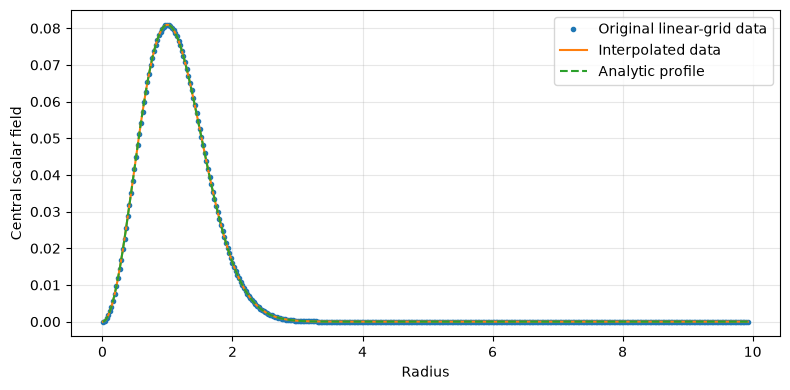

In [7]:
u_old = np.asarray(old_state[matter.idx_u, physical])
u_new = np.asarray(transferred_state[matter.idx_u, physical_new])
u_exact = np.asarray(scalar_profile(new_r[physical_new], A, sigma))

max_abs_error = np.max(np.abs(u_new - u_exact))
profile_scale = np.max(np.abs(u_exact))
max_scaled_error = max_abs_error / profile_scale if profile_scale > 0 else 0.0

print(f"Maximum absolute scalar-profile error: {max_abs_error:.6e}")
print(f"Maximum scaled scalar-profile error:  {max_scaled_error:.6e}")

plt.figure(figsize=(8, 4))
plt.plot(r_physical, u_old, ".", label="Original linear-grid data")
plt.plot(new_r[physical_new], u_new, "-", label="Interpolated data")
plt.plot(new_r[physical_new], u_exact, "--", label="Analytic profile")
plt.xlabel("Radius")
plt.ylabel("Central scalar field")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# DEBUGGING

In [12]:
def solve_regrid_test_segment(y0, t_start, t_end, test_grid, test_background, dt_segment):
    def rhs(t, state, args):
        return get_rhs(t, state, test_grid, test_background, matter)

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(test_grid.NUM_VARS, test_grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS] <= 5e-3

    def save_central_scalar(t, state, args):
        state_grid = state.reshape(test_grid.NUM_VARS, test_grid.N)
        return state_grid[matter.idx_u, NUM_GHOSTS]

    def save_central_lapse(t, state, args):
        state_grid = state.reshape(test_grid.NUM_VARS, test_grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS]

    saveat = dfx.SaveAt(subs=[
        dfx.SubSaveAt(t1=True),
        dfx.SubSaveAt(t0=True, steps=True, fn=save_central_scalar),
        dfx.SubSaveAt(t0=True, steps=True, fn=save_central_lapse),
    ])

    max_steps = max(2000,int(np.ceil((t_end - t_start) / dt_segment)) + 10,)

    return dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs),
        solver=dfx.Dopri5(),
        t0=t_start,
        t1=t_end,
        dt0=dt_segment,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=saveat,
        adjoint=dfx.ForwardMode(),
        event=dfx.Event(collapse_condition),
        max_steps=max_steps,
    )


# Run to the scheduled regrid time on the existing linear grid.
A_regrid_test = 0.37205123
t_test_final = 9.375
t_regrid = 6.0


state0 = make_initial_state(A_regrid_test)
solution_before = solve_regrid_test_segment(
    state0, 0.0, t_regrid, grid, background, dt0
)

if solution_before.result == dfx.RESULTS.event_occurred:
    print("Collapse event occurred before the scheduled regrid.")
else:
    state_at_regrid = solution_before.ys[0]
    if state_at_regrid.ndim == 2:
        state_at_regrid = state_at_regrid[-1]
    state_at_regrid = state_at_regrid.reshape(grid.NUM_VARS, grid.N)

    old_dx = float(spacing.min_dr)
    regrid_params = SinhSpacing.get_parameters(
        r_max=r_max,
        min_dr=old_dx / 2.0,
        max_dr=old_dx,
        extent=SpacingExtent.HALF,
    )

    # David rounds the new point count up to a multiple of 64.
    raw_n = regrid_params["num_points"]
    regrid_params["num_points"] = ((raw_n + 63) // 64) * 64

    spacing_after = SinhSpacing(**regrid_params)
    grid_after = Grid(spacing_after, state_vector)
    background_after = FlatSphericalBackground(grid_after.r)

    new_r = spacing_after.dnr_dxn[0]
    new_x_on_old_grid = spacing.x_of_r(new_r)

    state_after_regrid = interpolate_to_new_grid(
        state_at_regrid,
        spacing.x,
        new_x_on_old_grid,
    )
    state_after_regrid = enforce_det_constraint(state_after_regrid)
    state_after_regrid = grid_after.fill_boundaries(state_after_regrid)

    dt_after = dt0 * float(spacing_after.min_dr) / float(spacing.min_dr)
    print(f"Time step after regrid: {dt_after:.6g}")

    solution_after = solve_regrid_test_segment(
        state_after_regrid.reshape(-1),
        t_regrid,
        t_test_final,
        grid_after,
        background_after,
        dt_after,
    )

    final_state = solution_after.ys[0]
    if final_state.ndim == 2:
        final_state = final_state[-1]
    final_state = final_state.reshape(grid_after.NUM_VARS, grid_after.N)

    print("Before-regrid Diffrax result:", solution_before.result)
    print("After-regrid Diffrax result:", solution_after.result)
    print("Post-regrid grid points:", grid_after.N)
    print("Post-regrid final state finite:",
          bool(jnp.all(jnp.isfinite(final_state))))
    print("Post-regrid final central lapse:",
          float(final_state[idx_lapse, NUM_GHOSTS]))

Time step after regrid: 0.00118711
Before-regrid Diffrax result: diffrax._solution.RESULTS<>
After-regrid Diffrax result: diffrax._solution.RESULTS<>
Post-regrid grid points: 640
Post-regrid final state finite: False
Post-regrid final central lapse: nan


In [29]:
# Build the starting Sinh grid from the existing Linear grid's spacing.
linear_min_dr = float(spacing.min_dr)

params_sinh0 = SinhSpacing.get_parameters(
    r_max=r_max,
    min_dr=linear_min_dr / 2.0,
    max_dr=linear_min_dr,
    extent=SpacingExtent.HALF,
)

# Round the point count up to David's multiple of 64.
raw_n = params_sinh0["num_points"]
params_sinh0["num_points"] = ((raw_n + 63) // 64) * 64

spacing_sinh0 = SinhSpacing(**params_sinh0)
grid_sinh0 = Grid(spacing_sinh0, state_vector)
background_sinh0 = FlatSphericalBackground(grid_sinh0.r)

# Create initial data on the existing Linear grid, then transfer it to Sinh.
state0_linear = make_initial_state(A_regrid_test)
state0_linear = state0_linear.reshape(grid.NUM_VARS, grid.N)

x_targets_sinh0 = spacing.x_of_r(grid_sinh0.r)
state0_sinh = interpolate_to_new_grid(
    state0_linear,
    spacing.x,
    x_targets_sinh0,
)
state0_sinh = enforce_det_constraint(state0_sinh)
state0_sinh = grid_sinh0.fill_boundaries(state0_sinh)

# Scale the timestep with the new minimum spacing.
dt_sinh0 = dt0 * float(spacing_sinh0.min_dr) / linear_min_dr

# Evolve on the Sinh grid up to the regrid time.
solution_before_sinh_regrid = solve_regrid_test_segment(
    state0_sinh.reshape(-1),
    0.0,
    t_regrid,
    grid_sinh0,
    background_sinh0,
    dt_sinh0,
)

print("Sinh-grid segment result:", solution_before_sinh_regrid.result)
print("Sinh-grid points:", grid_sinh0.N)
print("Sinh-grid timestep:", dt_sinh0)

Sinh-grid segment result: diffrax._solution.RESULTS<>
Sinh-grid points: 640
Sinh-grid timestep: 0.0011871075704693351


In [30]:
if solution_before_sinh_regrid.result != dfx.RESULTS.successful:
    print("The first Sinh-grid segment did not finish successfully; skipping regrid.")
else:
    # Extract the saved state at t_regrid.
    state_at_regrid = solution_before_sinh_regrid.ys[0]
    if state_at_regrid.ndim == 2:
        state_at_regrid = state_at_regrid[-1]
    state_at_regrid = state_at_regrid.reshape(
        grid_sinh0.NUM_VARS, grid_sinh0.N
    )

    # Build a finer Sinh grid: halve min_dr and set max_dr to the old min_dr.
    old_min_dr = float(spacing_sinh0.min_dr)
    params_sinh1 = SinhSpacing.get_parameters(
        r_max=r_max,
        min_dr=old_min_dr / 2.0,
        max_dr=old_min_dr,
        extent=SpacingExtent.HALF,
    )

    # Round the point count up to David's multiple of 64.
    raw_n = params_sinh1["num_points"]
    params_sinh1["num_points"] = ((raw_n + 63) // 64) * 64

    spacing_sinh1 = SinhSpacing(**params_sinh1)
    grid_sinh1 = Grid(spacing_sinh1, state_vector)
    background_sinh1 = FlatSphericalBackground(grid_sinh1.r)

    # Transfer from the old Sinh grid to the new Sinh grid.
    x_targets_sinh1 = spacing_sinh0.x_of_r(grid_sinh1.r)
    state_sinh1 = interpolate_to_new_grid(
        state_at_regrid,
        spacing_sinh0.x,
        x_targets_sinh1,
    )
    state_sinh1 = enforce_det_constraint(state_sinh1)
    state_sinh1 = grid_sinh1.fill_boundaries(state_sinh1)

    # Scale the timestep with the new minimum spacing.
    dt_sinh1 = dt_sinh0 * (
        float(spacing_sinh1.min_dr) / old_min_dr
    )

    solution_after_sinh_regrid = solve_regrid_test_segment(
        state_sinh1.reshape(-1),
        t_regrid,
        t_test_final,
        grid_sinh1,
        background_sinh1,
        dt_sinh1,
    )

    print("Second Sinh-grid result:", solution_after_sinh_regrid.result)
    print("Second Sinh-grid points:", grid_sinh1.N)
    print("Second Sinh-grid timestep:", dt_sinh1)

Second Sinh-grid result: diffrax._solution.RESULTS<>
Second Sinh-grid points: 1280
Second Sinh-grid timestep: 0.0005919262572146388


In [32]:
times = np.asarray(solution_after_sinh_regrid.ts[2])
lapse = np.asarray(solution_after_sinh_regrid.ys[2])

bad = np.flatnonzero(np.isfinite(times) & ~np.isfinite(lapse))

if len(bad):
    i = bad[0]
    print("First nonfinite central lapse at t =", times[i])
    if i > 0 and np.isfinite(lapse[i - 1]):
        print("Previous finite lapse =", lapse[i - 1])
        print("Previous time =", times[i - 1])
else:
    print("No nonfinite central lapse in the saved step history.")

First nonfinite central lapse at t = 6.000591926257215
Previous finite lapse = 0.5212466268292414
Previous time = 6.0


In [33]:
state_check = np.asarray(state_sinh1)
rhs_check = np.asarray(
    get_rhs(
        t_regrid,
        state_sinh1.reshape(-1),
        grid_sinh1,
        background_sinh1,
        matter,
    )
).reshape(grid_sinh1.NUM_VARS, grid_sinh1.N)

print("Transferred state finite:", np.isfinite(state_check).all())
print("RHS finite:", np.isfinite(rhs_check).all())
print("Central lapse after transfer:",
      state_check[idx_lapse, NUM_GHOSTS])
print("Central lapse RHS:", rhs_check[idx_lapse, NUM_GHOSTS])

Transferred state finite: True
RHS finite: False
Central lapse after transfer: 0.5212466268292414
Central lapse RHS: -0.411520201122919


In [34]:
names = [
    "phi", "hrr", "htt", "hpp", "K", "arr", "att",
    "app", "lambdar", "shiftr", "br", "lapse", "u", "v",
]

bad = np.argwhere(~np.isfinite(rhs_check))
print("Nonfinite RHS entries:", len(bad))

for var_i, grid_i in bad[:20]:
    print(
        names[var_i],
        "grid index =", grid_i,
        "r =", float(grid_sinh1.r[grid_i]),
        "state =", float(state_check[var_i, grid_i]),
    )

Nonfinite RHS entries: 7645
phi grid index = 702 r = 4.537763849798962 state = 42419755.80981445
phi grid index = 716 r = 4.644306032664885 state = 49186958.580566406
phi grid index = 720 r = 4.67492364364315 state = 51259911.880371094
phi grid index = 721 r = 4.682590465901209 state = 51788146.528808594
phi grid index = 736 r = 4.798195476559225 state = 60207514.275634766
phi grid index = 738 r = 4.8136956940611135 state = 61402410.04345703
phi grid index = 739 r = 4.821453484185162 state = 62006422.935302734
phi grid index = 740 r = 4.829216406232582 state = 62614840.10571289
phi grid index = 741 r = 4.836984468466179 state = 63227682.314208984
phi grid index = 742 r = 4.844757679154224 state = 63844970.36669922
phi grid index = 743 r = 4.852536046570474 state = 64466725.11352539
phi grid index = 744 r = 4.860319578994171 state = 65092967.45263672
phi grid index = 745 r = 4.868108284710056 state = 65723718.32299805
phi grid index = 746 r = 4.875902172008376 state = 66358998.71191406


In [35]:
x_source_sinh0 = spacing_sinh0.x_of_r(grid_sinh0.r)
x_target_sinh1 = spacing_sinh0.x_of_r(grid_sinh1.r)

state_sinh1_raw = interpolate_to_new_grid(
    state_at_regrid,
    x_source_sinh0,
    x_target_sinh1,
)

print("Source coordinate mismatch:",
      float(jnp.max(jnp.abs(x_source_sinh0 - spacing_sinh0.x))))
print("Transferred phi finite:",
      bool(jnp.all(jnp.isfinite(state_sinh1_raw[0]))))
print("Maximum absolute transferred phi:",
      float(jnp.max(jnp.abs(state_sinh1_raw[0]))))

Source coordinate mismatch: 1.681265053373153
Transferred phi finite: True
Maximum absolute transferred phi: 0.16074543976370023


In [31]:
final_saved = solution_after_sinh_regrid.ys[0]
if final_saved.ndim == 2:
    final_saved = final_saved[-1]

final_state_sinh1 = final_saved.reshape(
    grid_sinh1.NUM_VARS, grid_sinh1.N
)

print("Final state finite:",
      bool(jnp.all(jnp.isfinite(final_state_sinh1))))
print("Final central lapse:",
      float(final_state_sinh1[idx_lapse, NUM_GHOSTS]))

Final state finite: False
Final central lapse: nan


In [36]:
state_sinh1 = enforce_det_constraint(state_sinh1_raw)
state_sinh1 = grid_sinh1.fill_boundaries(state_sinh1)

rhs_check = get_rhs(
    t_regrid,
    state_sinh1.reshape(-1),
    grid_sinh1,
    background_sinh1,
    matter,
)

print("Transferred state finite:",
      bool(jnp.all(jnp.isfinite(state_sinh1))))
print("RHS finite:",
      bool(jnp.all(jnp.isfinite(rhs_check))))

Transferred state finite: True
RHS finite: True


In [37]:
solution_after_sinh_regrid = solve_regrid_test_segment(
    state_sinh1.reshape(-1),
    t_regrid,
    t_test_final,
    grid_sinh1,
    background_sinh1,
    dt_sinh1,
)

final_saved = solution_after_sinh_regrid.ys[0]
if final_saved.ndim == 2:
    final_saved = final_saved[-1]

final_state_sinh1 = final_saved.reshape(
    grid_sinh1.NUM_VARS, grid_sinh1.N
)

print("Result:", solution_after_sinh_regrid.result)
print("Final state finite:",
      bool(jnp.all(jnp.isfinite(final_state_sinh1))))
print("Final central lapse:",
      float(final_state_sinh1[idx_lapse, NUM_GHOSTS]))

Result: diffrax._solution.RESULTS<>
Final state finite: True
Final central lapse: 0.8123345687752043


In [13]:
def report_segment(name, solution):
    print(f"\n{name}: {solution.result}")

    for stream_index, label in [(1, "central scalar"), (2, "central lapse")]:
        times = np.asarray(solution.ts[stream_index])
        values = np.asarray(solution.ys[stream_index])
        valid_times = np.isfinite(times)
        bad = np.flatnonzero(valid_times & ~np.isfinite(values))

        if len(bad):
            print(f"  First nonfinite {label}: t={times[bad[0]]:.6f}")
        else:
            print(f"  No nonfinite {label} samples")

    final_saved_state = np.asarray(solution.ys[0])
    if final_saved_state.ndim > 1:
        final_saved_state = final_saved_state[-1]
    print("  Final saved full state finite:",
          np.isfinite(final_saved_state).all())


print("State immediately after interpolation finite:",
      bool(jnp.all(jnp.isfinite(state_after_regrid))))

report_segment("Before regrid", solution_before)
report_segment("After regrid", solution_after)

State immediately after interpolation finite: True

Before regrid: diffrax._solution.RESULTS<>
  No nonfinite central scalar samples
  No nonfinite central lapse samples
  Final saved full state finite: True

After regrid: diffrax._solution.RESULTS<>
  First nonfinite central scalar: t=7.897547
  First nonfinite central lapse: t=7.897547
  Final saved full state finite: False


In [14]:
control_solution_after = solve_regrid_test_segment(
    state_at_regrid.reshape(-1),
    t_regrid,
    8.2,
    grid,
    background,
    dt_after,
)

report_segment("Control: keep linear grid, use smaller timestep",
               control_solution_after)


Control: keep linear grid, use smaller timestep: diffrax._solution.RESULTS<>
  No nonfinite central scalar samples
  No nonfinite central lapse samples
  Final saved full state finite: True


In [16]:
variable_names = [
    "phi", "hrr", "htt", "hpp", "K", "arr", "att",
    "app", "lambdar", "shiftr", "br", "lapse", "u", "v",
]

def rhs_summary(label, state, test_grid, test_background):
    rhs = get_rhs(
        t_regrid,
        state.reshape(-1),
        test_grid,
        test_background,
        matter,
    )
    rhs = np.asarray(rhs).reshape(test_grid.NUM_VARS, test_grid.N)
    interior = slice(NUM_GHOSTS, -NUM_GHOSTS)

    print(f"\n{label}: all RHS values finite:",
          bool(np.isfinite(rhs[:, interior]).all()))

    for i, name in enumerate(variable_names):
        values = np.abs(rhs[i, interior])
        max_index = int(np.nanargmax(values))
        radius = np.asarray(test_grid.r[interior])[max_index]
        print(f"{name:8s} max |RHS|={values[max_index]:.6e} at r={radius:.6g}")


rhs_summary("Before regrid", state_at_regrid, grid, background)
rhs_summary("After regrid", state_after_regrid, grid_after, background_after)


Before regrid: all RHS values finite: True
phi      max |RHS|=1.221963e+00 at r=0.0125786
hrr      max |RHS|=1.956459e+00 at r=0.0377358
htt      max |RHS|=9.442675e-01 at r=0.0377358
hpp      max |RHS|=9.442675e-01 at r=0.0377358
K        max |RHS|=3.838459e+02 at r=0.0125786
arr      max |RHS|=1.247027e+02 at r=0.0377358
att      max |RHS|=5.440106e+01 at r=0.0377358
app      max |RHS|=5.440106e+01 at r=0.0377358
lambdar  max |RHS|=4.298333e+01 at r=0.0125786
shiftr   max |RHS|=2.433794e+00 at r=0.0377358
br       max |RHS|=3.218373e+01 at r=0.0125786
lapse    max |RHS|=1.440142e+00 at r=0.0628931
u        max |RHS|=2.530025e+00 at r=0.0125786
v        max |RHS|=1.374956e+02 at r=0.0125786

After regrid: all RHS values finite: True
phi      max |RHS|=1.398325e+00 at r=0.00597287
hrr      max |RHS|=1.868372e+00 at r=0.0298645
htt      max |RHS|=9.117739e-01 at r=0.0298645
hpp      max |RHS|=9.127572e-01 at r=0.0298645
K        max |RHS|=4.589930e+02 at r=0.00597287
arr      max |RHS|

In [18]:
from bssn.constraintsdiagnostic import get_constraints_diagnostic


def constraint_summary(label, state, test_grid, test_background):
    hamiltonian, momentum = get_constraints_diagnostic(
        np.asarray(state).reshape(1, -1),
        np.array([t_regrid]),
        test_grid,
        test_background,
        matter,
    )

    interior = slice(NUM_GHOSTS, -NUM_GHOSTS)
    hamiltonian = np.asarray(hamiltonian)[0, interior]
    momentum = np.asarray(momentum)[0, interior]

    print(f"\n{label}:")
    print(f"max |Hamiltonian constraint|: {np.max(np.abs(hamiltonian)):.6e}")
    print(f"max |Momentum constraint|:    {np.max(np.abs(momentum)):.6e}")


constraint_summary("Before regrid", state_at_regrid, grid, background)
constraint_summary("After regrid", state_after_regrid, grid_after, background_after)


Before regrid:
max |Hamiltonian constraint|: 7.011636e+01
max |Momentum constraint|:    4.476935e+01

After regrid:
max |Hamiltonian constraint|: 1.145173e+02
max |Momentum constraint|:    9.383834e+01


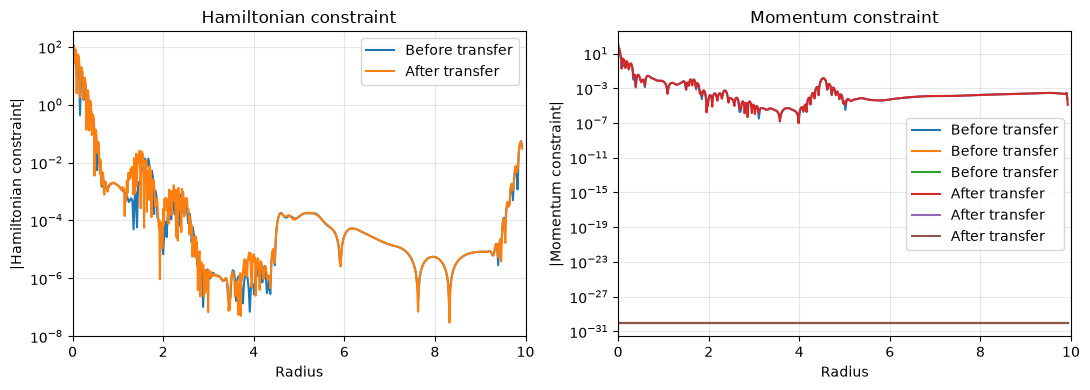

In [19]:
def constraint_profiles(state, test_grid, test_background):
    ham, mom = get_constraints_diagnostic(
        np.asarray(state).reshape(1, -1),
        np.array([t_regrid]),
        test_grid,
        test_background,
        matter,
    )
    return np.asarray(ham)[0], np.asarray(mom)[0]


ham_before, mom_before = constraint_profiles(
    state_at_regrid, grid, background
)
ham_after, mom_after = constraint_profiles(
    state_after_regrid, grid_after, background_after
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, before, after, title in [
    (axes[0], ham_before, ham_after, "Hamiltonian constraint"),
    (axes[1], mom_before, mom_after, "Momentum constraint"),
]:
    ax.semilogy(
        grid.r[physical],
        np.maximum(np.abs(before[physical]), 1e-30),
        label="Before transfer",
    )
    ax.semilogy(
        grid_after.r[physical_new],
        np.maximum(np.abs(after[physical_new]), 1e-30),
        label="After transfer",
    )
    ax.set_xlabel("Radius")
    ax.set_ylabel(f"|{title}|")
    ax.set_title(title)
    ax.set_xlim(0, r_max)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

In [20]:
state0_linear = make_initial_state(A_regrid_test).reshape(
    grid.NUM_VARS, grid.N
)

x_targets0 = spacing.x_of_r(grid_after.r)
state0_sinh = interpolate_to_new_grid(
    state0_linear,
    spacing.x,
    x_targets0,
)
state0_sinh = enforce_det_constraint(state0_sinh)
state0_sinh = grid_after.fill_boundaries(state0_sinh)

solution_sinh_from_start = solve_regrid_test_segment(
    state0_sinh.reshape(-1),
    0.0,
    8.0,
    grid_after,
    background_after,
    dt_after,
)

report_segment("Sinh grid from the start", solution_sinh_from_start)


Sinh grid from the start: diffrax._solution.RESULTS<>
  No nonfinite central scalar samples
  No nonfinite central lapse samples
  Final saved full state finite: True


In [23]:
import numpy as np

# Get the last saved full state from the run on the original grid.
saved_times = np.asarray(solution_before.ts[0])
saved_states = np.asarray(solution_before.ys[0])

valid = np.isfinite(saved_times)
state_at_regrid = saved_states[valid][-1].reshape(grid.NUM_VARS, grid.N)

print("State time:", saved_times[valid][-1])
print("State shape:", state_at_regrid.shape)

# Use the same Sinh coordinate mapping and interpolation helper
# as in your successful Linear -> Sinh test.
x_linear = spacing.x_of_r(grid.r)
x_sinh = spacing.x_of_r(grid_after.r)

# Transfer Linear -> Sinh, applying the same corrections as the real regrid.
state_on_sinh = interpolate_to_new_grid(
    state_at_regrid, x_linear, x_sinh
)
state_on_sinh = enforce_det_constraint(state_on_sinh)
state_on_sinh = grid_after.fill_boundaries(state_on_sinh)

# Transfer Sinh -> Linear and apply the corresponding corrections.
state_back = interpolate_to_new_grid(
    state_on_sinh, x_sinh, x_linear
)
state_back = enforce_det_constraint(state_back)
state_back = grid.fill_boundaries(state_back)

# Compare the original and round-tripped states on physical grid points.
physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
difference = np.abs(
    np.asarray(state_back)[:, physical]
    - np.asarray(state_at_regrid)[:, physical]
)

print("All round-tripped values finite:", np.isfinite(state_back).all())
print("Maximum absolute difference by variable:")
for i, error in enumerate(np.max(difference, axis=1)):
    print(f"  variable {i}: {error:.6e}")

State time: 6.0
State shape: (14, 401)
All round-tripped values finite: True
Maximum absolute difference by variable:
  variable 0: 1.383913e-04
  variable 1: 4.239302e-05
  variable 2: 2.463708e-05
  variable 3: 3.820673e-04
  variable 4: 1.706979e-02
  variable 5: 6.985184e-02
  variable 6: 3.427536e-02
  variable 7: 3.427536e-02
  variable 8: 5.476770e-02
  variable 9: 4.208191e-04
  variable 10: 3.747090e-02
  variable 11: 1.158690e-03
  variable 12: 6.360014e-04
  variable 13: 2.861286e-03


In [24]:
names = [
    "phi", "hrr", "htt", "hpp", "K", "arr", "att",
    "app", "lambdar", "shiftr", "br", "lapse", "u", "v",
]

original_physical = np.asarray(state_at_regrid)[:, physical]
r_physical = np.asarray(grid.r)[physical]

for i, name in enumerate(names):
    peak = np.argmax(difference[i])
    scale = np.max(np.abs(original_physical[i]))
    relative_error = np.max(difference[i]) / max(scale, 1e-14)
    print(
        f"{name:8s} max abs={np.max(difference[i]):.3e}, "
        f"relative={relative_error:.3e}, "
        f"at r={r_physical[peak]:.6g}"
    )

phi      max abs=1.384e-04, relative=5.620e-04, at r=0.0125786
hrr      max abs=4.239e-05, relative=4.677e-04, at r=0.0628931
htt      max abs=2.464e-05, relative=5.803e-04, at r=0.0628931
hpp      max abs=3.821e-04, relative=8.999e-03, at r=0.0628931
K        max abs=1.707e-02, relative=1.277e-02, at r=0.0377358
arr      max abs=6.985e-02, relative=1.688e-02, at r=0.0125786
att      max abs=3.428e-02, relative=1.724e-02, at r=0.0125786
app      max abs=3.428e-02, relative=1.724e-02, at r=0.0125786
lambdar  max abs=5.477e-02, relative=1.541e-02, at r=0.0125786
shiftr   max abs=4.208e-04, relative=4.398e-03, at r=0.0377358
br       max abs=3.747e-02, relative=1.520e-02, at r=0.0125786
lapse    max abs=1.159e-03, relative=1.240e-03, at r=0.0125786
u        max abs=6.360e-04, relative=1.578e-03, at r=0.0125786
v        max abs=2.861e-03, relative=8.023e-04, at r=0.0628931


In [25]:
# Round trip using interpolation only, without determinant or boundary corrections.
state_sinh_raw = interpolate_to_new_grid(
    state_at_regrid, x_linear, x_sinh
)
state_back_raw = interpolate_to_new_grid(
    state_sinh_raw, x_sinh, x_linear
)

original_physical = np.asarray(state_at_regrid)[:, physical]
raw_back_physical = np.asarray(state_back_raw)[:, physical]
raw_difference = np.abs(raw_back_physical - original_physical)

for i, name in enumerate(names):
    scale = np.max(np.abs(original_physical[i]))
    relative_error = np.max(raw_difference[i]) / max(scale, 1e-14)
    print(
        f"{name:8s} max abs={np.max(raw_difference[i]):.3e}, "
        f"relative={relative_error:.3e}"
    )

phi      max abs=1.439e-02, relative=5.844e-02
hrr      max abs=2.840e-04, relative=3.133e-03
htt      max abs=1.416e-04, relative=3.336e-03
hpp      max abs=1.416e-04, relative=3.336e-03
K        max abs=1.891e-02, relative=1.414e-02
arr      max abs=9.891e-02, relative=2.390e-02
att      max abs=4.954e-02, relative=2.492e-02
app      max abs=4.954e-02, relative=2.492e-02
lambdar  max abs=1.383e-01, relative=3.891e-02
shiftr   max abs=8.055e-04, relative=8.418e-03
br       max abs=9.792e-02, relative=3.971e-02
lapse    max abs=7.803e-02, relative=8.348e-02
u        max abs=2.357e-02, relative=5.846e-02
v        max abs=2.160e-01, relative=6.056e-02


In [26]:
physical_after = slice(NUM_GHOSTS, -NUM_GHOSTS)

raw = np.asarray(state_sinh_raw)[:, physical_after]
corrected = np.asarray(state_on_sinh)[:, physical_after]
correction_difference = np.abs(corrected - raw)

for i, name in enumerate(names):
    scale = np.max(np.abs(raw[i]))
    relative_change = np.max(correction_difference[i]) / max(scale, 1e-14)
    print(
        f"{name:8s} correction change="
        f"{np.max(correction_difference[i]):.3e}, "
        f"relative={relative_change:.3e}"
    )

phi      correction change=0.000e+00, relative=0.000e+00
hrr      correction change=0.000e+00, relative=0.000e+00
htt      correction change=0.000e+00, relative=0.000e+00
hpp      correction change=4.542e-04, relative=1.069e-02
K        correction change=0.000e+00, relative=0.000e+00
arr      correction change=0.000e+00, relative=0.000e+00
att      correction change=0.000e+00, relative=0.000e+00
app      correction change=0.000e+00, relative=0.000e+00
lambdar  correction change=0.000e+00, relative=0.000e+00
shiftr   correction change=0.000e+00, relative=0.000e+00
br       correction change=0.000e+00, relative=0.000e+00
lapse    correction change=0.000e+00, relative=0.000e+00
u        correction change=0.000e+00, relative=0.000e+00
v        correction change=0.000e+00, relative=0.000e+00


In [27]:
source = np.array(state_at_regrid, copy=True)

# Raw path: interpolation only.
raw_sinh = interpolate_to_new_grid(source.copy(), x_linear, x_sinh)
raw_back = interpolate_to_new_grid(raw_sinh.copy(), x_sinh, x_linear)

# Corrected path: same interpolation, with the regrid corrections.
corrected_sinh = interpolate_to_new_grid(source.copy(), x_linear, x_sinh)
corrected_sinh = enforce_det_constraint(corrected_sinh)
corrected_sinh = grid_after.fill_boundaries(corrected_sinh)

corrected_back = interpolate_to_new_grid(
    np.array(corrected_sinh, copy=True), x_sinh, x_linear
)
corrected_back = enforce_det_constraint(corrected_back)
corrected_back = grid.fill_boundaries(corrected_back)

# Compare the two returned Linear-grid states.
raw_phys = np.asarray(raw_back)[:, physical]
corrected_phys = np.asarray(corrected_back)[:, physical]
path_difference = np.abs(corrected_phys - raw_phys)

for i, name in enumerate(names):
    print(f"{name:8s} difference between paths={np.max(path_difference[i]):.3e}")

phi      difference between paths=1.425e-02
hrr      difference between paths=2.840e-04
htt      difference between paths=1.416e-04
hpp      difference between paths=3.574e-04
K        difference between paths=8.246e-03
arr      difference between paths=2.906e-02
att      difference between paths=1.526e-02
app      difference between paths=1.526e-02
lambdar  difference between paths=8.349e-02
shiftr   difference between paths=8.286e-04
br       difference between paths=6.045e-02
lapse    difference between paths=7.803e-02
u        difference between paths=2.420e-02
v        difference between paths=2.153e-01


In [28]:
physical_indices = np.arange(grid.N)[physical]
r_physical = np.asarray(grid.r)[physical]

for i, name in enumerate(names):
    peak = np.argmax(path_difference[i])
    print(
        f"{name:8s} peak at r={r_physical[peak]:.6g}, "
        f"difference={path_difference[i, peak]:.3e}"
    )

# The interpolation helper uses a 7-point stencil, so also compare
# away from both edges of the physical grid.
interior = slice(4, -4)
print("\nMaximum path difference, excluding 4 physical points at each edge:")
for i, name in enumerate(names):
    print(f"{name:8s} {np.max(path_difference[i, interior]):.3e}")

phi      peak at r=0.0125786, difference=1.425e-02
hrr      peak at r=9.92453, difference=2.840e-04
htt      peak at r=9.92453, difference=1.416e-04
hpp      peak at r=0.0628931, difference=3.574e-04
K        peak at r=0.0125786, difference=8.246e-03
arr      peak at r=0.0125786, difference=2.906e-02
att      peak at r=0.0125786, difference=1.526e-02
app      peak at r=0.0125786, difference=1.526e-02
lambdar  peak at r=0.0125786, difference=8.349e-02
shiftr   peak at r=0.0125786, difference=8.286e-04
br       peak at r=0.0125786, difference=6.045e-02
lapse    peak at r=9.92453, difference=7.803e-02
u        peak at r=0.0125786, difference=2.420e-02
v        peak at r=0.0125786, difference=2.153e-01

Maximum path difference, excluding 4 physical points at each edge:
phi      0.000e+00
hrr      0.000e+00
htt      0.000e+00
hpp      1.676e-04
K        0.000e+00
arr      0.000e+00
att      0.000e+00
app      0.000e+00
lambdar  0.000e+00
shiftr   0.000e+00
br       0.000e+00
lapse    0.000e

## Evolution, classification & objective


In [ ]:
def evolve(amplitude, t_final=T):
    y0 = make_initial_state(amplitude) # builds state at t0

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter) # wrapper for Diffrax inputs

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        central_lapse = state_grid[idx_lapse, NUM_GHOSTS]
        return central_lapse <= 5e-3 # provisional collapse event

    def save_central_scalar(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        return state_grid[matter.idx_u, NUM_GHOSTS]

    def save_central_lapse(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS]

    save_times = jnp.linspace(0.0, t_final, num_output_times, endpoint=False)
    saveat = dfx.SaveAt(
        subs=[
            # Stream 0: full states at plot output times
            dfx.SubSaveAt(ts=save_times, t1=True),

            # Stream 1: central scalar at solver steps, used for L
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_scalar,
            ),

            # Stream 2: central lapse at solver steps, used for classification
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_lapse,
            ),
        ]
    )

    # Keep enough solver steps available when an unresolved run is extended.
    max_steps = max(2000, int(t_final / dt0) + 10)

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(), # Runge-Kutta solver
        t0=0.0,
        t1=t_final,
        dt0=dt0,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=saveat,
        adjoint=dfx.ForwardMode(),
        event=dfx.Event(collapse_condition),
        max_steps=max_steps,
    )

    return solution


def lapse_recovery_test(lapse_times, lapse_history):
    # Ignore unused inf padding after an event or after the final solver step.
    valid = jnp.isfinite(lapse_times) & jnp.isfinite(lapse_history)
    times = lapse_times[valid]
    lapse = lapse_history[valid]

    if lapse.shape[0] < 3:
        return False, 0.0, 0.0

    minimum_index = int(jnp.argmin(lapse))
    end_time = float(times[-1])
    start_time = end_time - RECOVERY_WINDOW_TIME
    in_window = times >= start_time

    if not bool(jnp.any(in_window)):
        return False, 0.0, 0.0

    first_window_index = int(jnp.argmax(in_window))
    tail_times = times[in_window]
    tail_lapse = lapse[in_window]

    # The lapse minimum must be earlier than this final recovery window.
    if minimum_index >= first_window_index or tail_lapse.shape[0] < 3:
        return False, 0.0, 0.0

    # Measure the total rebound from the minimum. This allows a run to count
    # as recovering even if the lapse has nearly levelled off by the end.
    final_lapse = float(lapse[-1])
    minimum_lapse = float(lapse[minimum_index])
    recovery_rise = final_lapse - minimum_lapse

    # Reject a clear late plunge after an earlier rebound. Small fluctuations
    # near a plateau are allowed.
    late_peak = float(jnp.max(tail_lapse))
    late_drop = late_peak - final_lapse

    changes = jnp.diff(tail_lapse)
    up_fraction = float(jnp.mean(changes > 0.0))
    recovering = (
        recovery_rise >= RECOVERY_MIN_RISE
        and late_drop <= RECOVERY_MAX_LATE_DROP
    )
    return bool(recovering), recovery_rise, up_fraction


# Calculate L, final lapse, and the lapse history.
def run_metrics(amplitude, t_final=T):
    solution = evolve(amplitude, t_final=t_final)

    # Central scalar history, saved at solver steps.
    central_times = solution.ts[1]
    central_u = solution.ys[1]
    valid = jnp.isfinite(central_times) & jnp.isfinite(central_u)
    u_clean = jnp.where(valid, central_u, 0.0)

    changes = jnp.abs(jnp.diff(u_clean))
    valid_pairs = valid[:-1] & valid[1:]
    L = jnp.sum(jnp.where(valid_pairs, changes, 0.0))

    # Full states use stream 0; ignore inf padding after an event.
    state_times = solution.ts[0]
    state_history = solution.ys[0]
    valid_state_times = jnp.isfinite(state_times)
    last_index = jnp.sum(valid_state_times.astype(jnp.int32)) - 1
    final_state = state_history[last_index].reshape(grid.NUM_VARS, grid.N)
    final_lapse = final_state[idx_lapse, NUM_GHOSTS]

    # Lapse stream 2 is auxiliary classification data, not differentiated.
    lapse_times = solution.ts[2]
    lapse_history = solution.ys[2]
    event_fired = solution.result == dfx.RESULTS.event_occurred
    run_successful = solution.result == dfx.RESULTS.successful
        # A successful Diffrax result can still contain nonfinite saved values
    # when using a constant timestep, so check the saved streams directly.
    finite_full_state_at_time = jnp.all(
        jnp.isfinite(state_history), axis=1
    )
    bad_full_state = jnp.any(
        valid_state_times & ~finite_full_state_at_time
    )

    bad_scalar = jnp.any(
        jnp.isfinite(central_times) & ~jnp.isfinite(central_u)
    )
    bad_lapse = jnp.any(
        jnp.isfinite(lapse_times) & ~jnp.isfinite(lapse_history)
    )
    nonfinite_saved_data = bad_full_state | bad_scalar | bad_lapse

    return jnp.stack([L, final_lapse]), (
        event_fired, run_successful, lapse_times, lapse_history,
        nonfinite_saved_data
    )


def evaluate_amplitude(A, t_final=T, check_recovery=False):
    amplitude = jnp.asarray(A, dtype=jnp.float64)

    # Differentiate only L and final_lapse with respect to amplitude.
    def metrics_for_amplitude(amplitude):
        return run_metrics(amplitude, t_final=t_final)

    values, derivatives, aux = jax.jvp(
        metrics_for_amplitude,
        (amplitude,),
        (jnp.ones_like(amplitude),),
        has_aux=True,
    )
    event_fired, run_successful, lapse_times, lapse_history, nonfinite_saved_data = aux

    # Keep only real solver-step values so each run can be plotted later.
    lapse_times_array = np.asarray(lapse_times)
    lapse_history_array = np.asarray(lapse_history)
    valid_lapse = np.isfinite(lapse_times_array) & np.isfinite(lapse_history_array)
    saved_lapse_times = lapse_times_array[valid_lapse].tolist()
    saved_lapse_history = lapse_history_array[valid_lapse].tolist()

    L = float(values[0])
    final_lapse = float(values[1])
    dL_dA = float(derivatives[0])
    if check_recovery:
        recovering, recovery_rise, recovery_up_fraction = lapse_recovery_test(
            lapse_times, lapse_history
        )
    else:
        recovering, recovery_rise, recovery_up_fraction = False, 0.0, 0.0
    if (
        bool(nonfinite_saved_data)
        or not all(isfinite(x) for x in (L, final_lapse))
    ):
        outcome = "failed"
    elif not bool(event_fired) and not bool(run_successful):
        outcome = "failed"
    elif bool(event_fired):
        outcome = "super"  # provisional until AHFinder is added
    elif final_lapse > SUBCRITICAL_FINAL_LAPSE:
        outcome = "sub"
    elif check_recovery and recovering:
        outcome = "sub"
    else:
        outcome = "unresolved"
    
    
    J = float(np.exp(-2.0 * L)) if isfinite(L) else float("nan")
    if isfinite(J) and isfinite(dL_dA):
        dJ_dA = -2.0 * J * dL_dA
    else:
        dJ_dA = float("nan")

    return {
        "A": float(A),
        "T": float(t_final),
        "L": L,
        "dL_dA": dL_dA,
        "J": J,
        "dJ_dA": dJ_dA,
        "gradient_valid": isfinite(dL_dA),
        "final_lapse": final_lapse,
        "recovery_rise": recovery_rise,
        "recovery_up_fraction": recovery_up_fraction,
        "lapse_times": saved_lapse_times,
        "lapse_history": saved_lapse_history,
        "outcome": outcome,
    }


In [40]:
import core.derivatives as derivative_module

print("Derivative functions:",
      [name for name in dir(derivative_module)
       if "stencil" in name.lower() or "deriv" in name.lower()])

print("Grid derivative attributes:",
      [name for name in dir(grid_sinh0.derivs)
       if not name.startswith("_")])

Derivative functions: ['Derivatives']
Grid derivative attributes: ['advec_x_matrix', 'compute_advec_x_matrix', 'compute_drn_matrix', 'compute_dxn_matrix', 'dnr_dxn', 'drn_matrix', 'dx', 'dxn_matrix', 'num_points']


In [41]:
import inspect

derivs = grid_sinh0.derivs

for name in ("dxn_matrix", "drn_matrix", "dx"):
    value = getattr(derivs, name)
    print(name, type(value), getattr(value, "shape", None))

print(
    "compute_dxn_matrix signature:",
    inspect.signature(derivs.compute_dxn_matrix),
)

dxn_matrix <class 'jaxlib._jax.ArrayImpl'> (7, 640, 640)
drn_matrix <class 'jaxlib._jax.ArrayImpl'> (7, 640, 640)
dx <class 'jaxlib._jax.ArrayImpl'> ()
compute_dxn_matrix signature: ()


In [42]:
x_comp = spacing_sinh0.x_of_r(grid_sinh0.r)
d2_x_squared = grid_sinh0.derivs.dxn_matrix[2] @ (x_comp**2)

interior = slice(NUM_GHOSTS + 4, -NUM_GHOSTS - 4)
print("Median computed d²(x²)/dx²:",
      float(jnp.median(d2_x_squared[interior])))
print("Grid dx:", float(grid_sinh0.derivs.dx))

Median computed d²(x²)/dx²: -1.6812064647098168e-06
Grid dx: 0.0020690618961898143


## Gradient-descent routine


In [ ]:
def objective_record(A, t_final):
    # evaluate_amplitude already returns L, J, dL/dA, and dJ/dA.
    return evaluate_amplitude(A, t_final=t_final, check_recovery=True)


def gradient_descent_from_scratch(
    A_start=0.22,
    t_final=7.5,
    max_iterations=8,
    initial_step_size=0.01,
    max_amplitude_step=0.02,
    max_backtracks=10,
    history=None,
):
    step_size = initial_step_size

    if history:
        history = list(history)
        current = history[-1]
        A = float(current["A"])

        print(
            f"Continuing from A={A:.8f}, "
            f"outcome={current['outcome']}, "
            f"L={current['L']:.6g}, J={current['J']:.6g}"
        )
    else:
        A = float(A_start)
        history = []

        current = objective_record(A, t_final)
        history.append(current)

        print(
            f"Start: A={A:.8f}, outcome={current['outcome']}, "
            f"L={current['L']:.6g}, J={current['J']:.6g}, "
            f"dJ/dA={current['dJ_dA']:.6g}"
        )

    if current["outcome"] == "failed":
        print("Stopping: the latest run failed.")
        return history

    for iteration in range(max_iterations):
        gradient = current["dJ_dA"]

        if not np.isfinite(gradient) or abs(gradient) < 1e-12:
            print("Stopping: the objective gradient is too small or invalid.")
            break

        accepted = False
        trial_step_size = step_size
        trial_max_amplitude_step = max_amplitude_step

        for _ in range(max_backtracks):
            # Gradient descent: A_new = A - step_size * dJ/dA
            change = -trial_step_size * gradient
            change = float(np.clip(
                change,
                -trial_max_amplitude_step,
                trial_max_amplitude_step,
            ))
            A_trial = A + change

            if A_trial <= 0.0 or A_trial == A:
                trial_step_size *= 0.5
                trial_max_amplitude_step *= 0.5
                continue

            trial = objective_record(A_trial, t_final)

            if (
                trial["outcome"] != "failed"
                and np.isfinite(trial["J"])
                and trial["J"] < current["J"]
            ):
                accepted = True
                break

            # Shrink both limits so the next trial tests a smaller amplitude change.
            trial_step_size *= 0.5
            trial_max_amplitude_step *= 0.5

        if not accepted:
            print("Stopping: no tested step lowered J.")
            break

        history.append(trial)
        A = A_trial
        current = trial
        step_size = min(initial_step_size, 1.25 * trial_step_size)

        print(
            f"Step {len(history) - 1}: A={A:.8f}, "
            f"outcome={current['outcome']}, "
            f"L={current['L']:.6g}, J={current['J']:.6g}, "
            f"dJ/dA={current['dJ_dA']:.6g}"
        )

    return history

## Load or initialize the search history

The saved history contains data only; rerun the definition cells above after restarting the kernel.


In [ ]:
CHECKPOINT_FILE = Path("gradient_descent_history.pkl")

if CHECKPOINT_FILE.exists():
    with CHECKPOINT_FILE.open("rb") as checkpoint:
        history = pickle.load(checkpoint)
    print(f"Loaded {len(history)} saved records from {CHECKPOINT_FILE}")
else:
    history = []
    print("No saved search history found; the next batch will start at A=0.22.")


## Run a short batch

Call this function manually when you want to run. It checkpoints the accepted history when the batch finishes.


In [ ]:
def run_gradient_descent_batch(
    t_final=T,
    max_iterations=1,
    initial_step_size=1e-4,
    max_amplitude_step=0.02,
    max_backtracks=4,
):
    """Run a short batch, then checkpoint the accepted history."""
    global history

    history = gradient_descent_from_scratch(
        A_start=0.22,
        t_final=t_final,
        max_iterations=max_iterations,
        initial_step_size=initial_step_size,
        max_amplitude_step=max_amplitude_step,
        max_backtracks=max_backtracks,
        history=history,
    )

    with CHECKPOINT_FILE.open("wb") as checkpoint:
        pickle.dump(history, checkpoint)

    print(f"Saved {len(history)} accepted records to {CHECKPOINT_FILE}")
    return history


## Plot the accepted minimisation records


In [ ]:
def plot_minimisation_history(history):
    plot_runs = [
        run for run in history
        if np.isfinite(run.get("A", np.nan))
        and np.isfinite(run.get("L", np.nan))
        and np.isfinite(run.get("J", np.nan))
    ]

    if not plot_runs:
        print("There are no finite minimisation records to plot yet.")
        return

    plot_runs = sorted(plot_runs, key=lambda run: run["A"])
    amplitudes = [run["A"] for run in plot_runs]
    L_values = [run["L"] for run in plot_runs]
    J_values = [run["J"] for run in plot_runs]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(amplitudes, L_values, "o-")
    axes[0].set_xlabel("Amplitude A")
    axes[0].set_ylabel("L")
    axes[0].set_title("L vs amplitude")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(amplitudes, J_values, "o-")
    axes[1].set_xlabel("Amplitude A")
    axes[1].set_ylabel("J")
    axes[1].set_title("J vs amplitude")
    axes[1].grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()


In [ ]:
plot_minimisation_history(history)
